# PIECEWISE PREDICTIONS

This notebook explores the effect of oscillating species on the accuracy of a linear approximation. The conclusion is that the effect is minimal.

In [1]:
import matplotlib.pyplot as plt  # type: ignore
import numpy as np  # type: ignore
import os
import pandas as pd  # type: ignore
from src.timecourse_iterator import TimecourseIterator, CurationChecker # type: ignore
from typing import Optional, cast, List, Union

import src.constants as cn
from src.score import Score
from src.system_discovery import SystemDiscovery  # type: ignore
from src.piecewise_system_discovery import PiecewiseSystemDiscovery
from src.timecourse_iterator import TimecourseIterator
from src.model import Model
from src.timecourse import Timecourse
from src.nl_curve import NLCurve

# Helpers

## getSystemDF

In [2]:
def getSystemDF(df: pd.DataFrame, model_num: Optional[int]=None, is_species: bool = False) -> pd.DataFrame:
    if model_num is not None:
        model_name = Model.getBiomodelName(model_num)#
        dff = df [df[cn.COL_SYSTEM_ID] == model_name]
    else:
        dff = df.copy()
    if is_species:
        sel = dff[cn.COL_AGGREGATION_TYPE] != cn.COL_AGGREGATION_TYPE_MODEL
    else:
        sel = dff[cn.COL_AGGREGATION_TYPE] == cn.COL_AGGREGATION_TYPE_MODEL
    return dff[sel]

#getSystemDF(DF)

## getPredictionDF

In [3]:
def getPredictionDF(
        threshold: Optional[float] = None,        # coefficient threshold
        removal: Optional[int] = None,            # 0: don't remove changepoints; 1: remove changepoints
        maxreduction: Optional[float] = None,     # max_accuracy_reduction
        manycp: Optional[int] =  None,            # many changepoints if 1 else 0
        curated: int = 1,                         # filtering models by curation.csv if 1, else 0
        ) -> pd.DataFrame:
    # Loads the correct file and returns a it as a dataframe. Eliminates models from curation.csv.
    all_ffiles = [f for f in os.listdir(cn.DATA_DIR) if "piecewise_predictions__" in f]
    ffiles = all_ffiles.copy()
    #
    if threshold is not None:
        ffiles = [f for f in ffiles if f"threshold_{threshold}" in f]
    if removal is not None:
        ffiles = [f for f in ffiles if f"removal_{removal}" in f]
    if maxreduction is not None:
        ffiles = [f for f in ffiles if f"maxreduction_{maxreduction}" in f]
    if manycp is not None:
        ffiles = [f for f in ffiles if f"manycp_{manycp}" in f]
    # Analyze the files selected
    if len(ffiles) > 1:
        raise ValueError(f"Ambiguous request. Found {ffiles}")
    if len(ffiles) == 0:
        raise ValueError(f"No file found. Choices are: {all_ffiles}")
    # Exclude models that have been removed by curation
    curation_exclusions = pd.read_csv(cn.CURATION_PATH)[cn.COL_SYSTEM_ID].to_list()
    path = os.path.join(cn.DATA_DIR, ffiles[0])
    df = pd.read_csv(path)
    sel = ~df[cn.COL_SYSTEM_ID].isin(curation_exclusions)
    return df[sel]

# Tests
"""
assert(len(getPredictionDF(maxreduction=0.05, threshold=0.001)) > 0)
try:
    # No file found
    _ = getPredictionDF(num_point=1)
    raise ValueError("Should fail this test")
except Exception as e:
    #print(e)
    pass
try:
    # Many files found
    _ = getPredictionDF()
    #raise ValueError("Should fail this test")
except Exception as e:
    #print(e)
    pass
print("OK!")
""" 

'\nassert(len(getPredictionDF(maxreduction=0.05, threshold=0.001)) > 0)\ntry:\n    # No file found\n    _ = getPredictionDF(num_point=1)\n    raise ValueError("Should fail this test")\nexcept Exception as e:\n    #print(e)\n    pass\ntry:\n    # Many files found\n    _ = getPredictionDF()\n    #raise ValueError("Should fail this test")\nexcept Exception as e:\n    #print(e)\n    pass\nprint("OK!")\n'

# Initializations

In [4]:
# Non-oscillating species timecourses
path = os.path.join(cn.DATA_DIR, f"find_oscillating_models.csv")
NONOSCILLATION_DF = pd.read_csv(path)
NONOSCILLATION_DF = NONOSCILLATION_DF [NONOSCILLATION_DF[cn.COL_FREQUENCIES] == "[]"]
NONOSCILLATION_DF = NONOSCILLATION_DF [NONOSCILLATION_DF[cn.COL_SPECIES_NAME] != cn.COL_AGGREGATION_TYPE_MODEL]
NONOSCILLATION_DF["key"] = [m + "_" + str(s) for m, s in zip(NONOSCILLATION_DF[cn.COL_SYSTEM_ID], NONOSCILLATION_DF[cn.COL_SPECIES_NAME])]
NONOSCILLATION_DF

,system_id,species_name,frequencies,endtime,key
17,BIOMD0000000042,GLC,[],300.0,BIOMD0000000042_GLC
19,BIOMD0000000042,FBP,[],300.0,BIOMD0000000042_FBP
20,BIOMD0000000042,GAP,[],300.0,BIOMD0000000042_GAP
21,BIOMD0000000042,NAD,[],300.0,BIOMD0000000042_NAD
22,BIOMD0000000042,NADH,[],300.0,BIOMD0000000042_NADH
...,...,...,...,...,...
4552,BIOMD0000001059,sursmac,[],7000.0,BIOMD0000001059_sursmac
4553,BIOMD0000001059,smacmit,[],7000.0,BIOMD0000001059_smacmit
4554,BIOMD0000001059,smac,[],7000.0,BIOMD0000001059_smac
4555,BIOMD0000001060,x1,[],40.0,BIOMD0000001060_x1


# Individual models

*** Processing BIOMD0000000005
*** Processing BIOMD0000000010


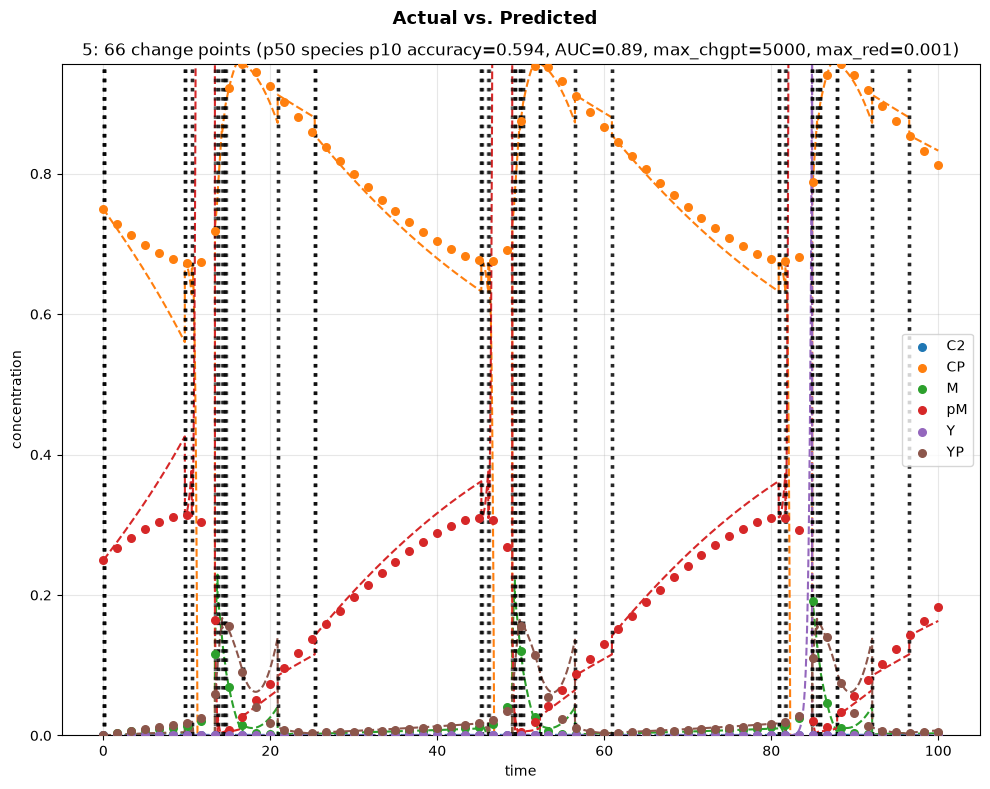

<Figure size 640x480 with 0 Axes>

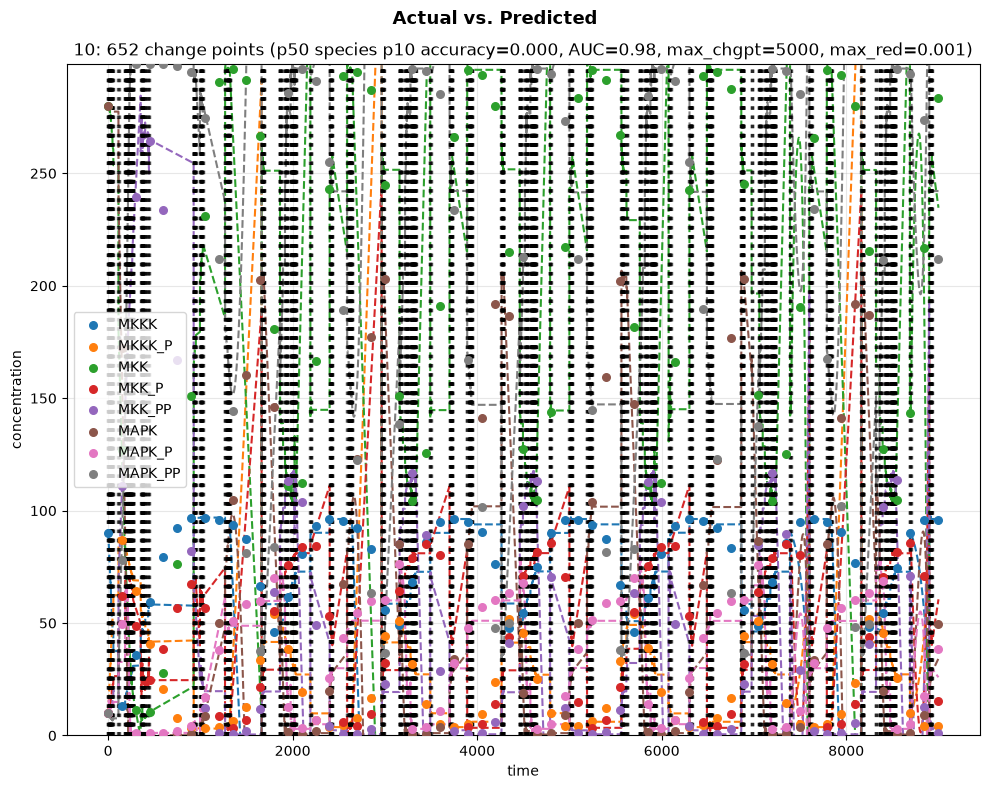

<Figure size 640x480 with 0 Axes>

In [5]:
timecourse_iter = TimecourseIterator(first_model_num=5, last_model_num=10)
max_changepoint = 5000
max_fractional_reduction = 1e-3
#for model_num in models:
for item in timecourse_iter:
    df = item.timecourse.timecourse_df
    try:
        print(f"*** Processing {item.model_name}")
        psd = PiecewiseSystemDiscovery(df, 
                max_changepoint=max_changepoint,
                is_changepoint_removal=True,
                max_fractional_reduction=max_fractional_reduction,
                model_id=item.model_name,
                                      )
        psd.fit()
        _ = psd.plotPiecewise(legend=False, num_true_point=60, is_nochangepoint_plot=False)
        ax = plt.gca()
        title = ax.get_title()
        new_title = title[:-2] + f", max_chgpt={max_changepoint}, max_red={max_fractional_reduction})"
        ax.set_title(new_title)
        plt.savefig(f"timecourse_{item.model_name}.pdf")
        plt.figure()
    except Exception as e:
        print(f"Could not process {item.model_name}: {e}")

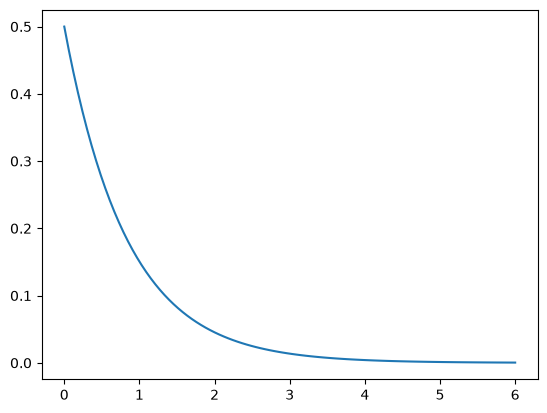

In [6]:
# Analysis of model 45. We can fit an exponential to Y or X
arr = np.linspace(0, 6, 100)
plt.plot(arr, 0.5*np.exp(-1.2*arr))

# Distribution of Number Species Across models

In [7]:
num_species_dct = {}
for item in TimecourseIterator():
    num_species_dct.update({item.model_name: len(item.timecourse.timecourse_df.columns)})
len(num_species_dct)

430

In [8]:
[m for m, s in num_species_dct.items() if s > 100]

['BIOMD0000000474', 'BIOMD0000000667']

Text(0.5, 1.0, 'Number Species per Model')

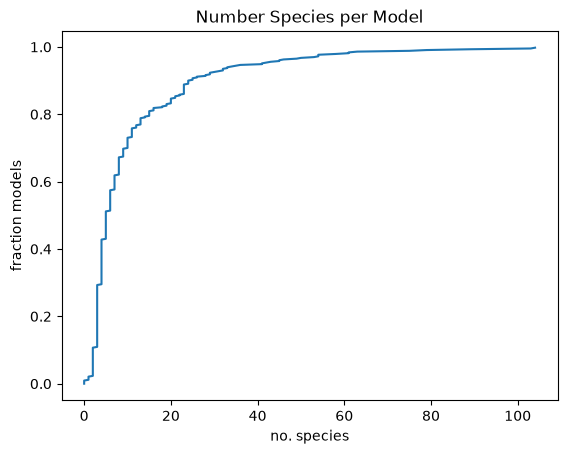

In [9]:
values = np.sort(list(num_species_dct.values()))
yv = np.array(range(len(values)))/len(values)
plt.plot(values, yv)
plt.xlabel("no. species")
plt.ylabel("fraction models")
plt.title("Number Species per Model")

Text(0.5, 1.0, 'CDF of Species by Model Size')

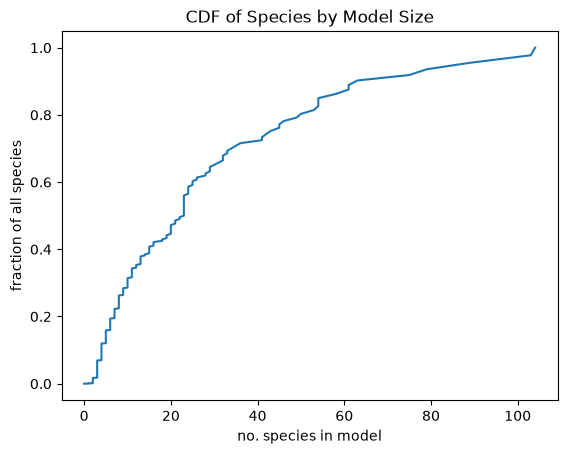

In [10]:
frac_species = np.cumsum(values)/np.sum(values)
_, ax = plt.subplots(1)
ax.plot(values, frac_species)
ax.set_xlabel("no. species in model")
ax.set_ylabel("fraction of all species")
ax.set_title("CDF of Species by Model Size")

# CDFs

## All Models

In [11]:
def getColumn(df: pd.DataFrame, col: str = "a80",  is_species: bool = True, max_changepoint: int = 10,
        is_oscillation: bool = True) -> pd.Series:
    if is_species:
        result_df = df[df[cn.COL_AGGREGATION_TYPE] != cn.COL_AGGREGATION_TYPE_MODEL]
    else:
        result_df = df[df[cn.COL_AGGREGATION_TYPE] == cn.COL_AGGREGATION_TYPE_MODEL]
    result_df = result_df[result_df[cn.COL_MAX_CHANGEPOINT] == max_changepoint]
    # Handle oscillations
    if not is_oscillation:
        pass
        
    return result_df[col]

In [12]:
def plotCDF(coefficient_threshold: Optional[float] = None, 
            is_species: bool = False,
            col="p10",
            is_non_oscillating: Optional[bool] = None,
            max_fractional_reduction: Optional[float] = None) -> pd.DataFrame:
    # Construct the dataframe to process
    if False:
        df = getPredictionDF(coefficient_threshold=coefficient_threshold,
            max_fractional_reduction=max_fractional_reduction)
    else:
        #path = os.path.join(cn.DATA_DIR, f"piecewise_predictions_{coefficient_threshold}_noremoval.csv")
        filename = "piecewise_predictions.csv"
        #filename = "piecewise_predictions__numpoint_100000__threshold_0.001__removal_1__maxreduction_5e-05__manycp_0.csv"
        #filename = "piecewise_predictions__numpoint_100000__threshold_0.001__removal_1__maxreduction_0.003__manycp_1.csv"
        #filename = "piecewise_predictions__numpoint_100000__threshold_0.001__removal_1__maxreduction_1e-08__manycp_0.csv"
        #filename = "piecewise_predictions__numpoint_100000__threshold_0.001__removal_1__maxreduction_0.001__manycp_0.csv"
        #filename = "piecewise_predictions__numpoint_10000__threshold_0.001__removal_1__maxreduction_0.01__manycp_1.csv"
        path = os.path.join(cn.DATA_DIR, filename)
        df = pd.read_csv(path)
#    df["key"] = NONOSCILLATION_DF[cn.COL_SYSTEM_ID] + "_" + NONOSCILLATION_DF[cn.COL_SPECIES_NAME]
#    if is_non_oscillating is not None:
#        df["key"] = NONOSCILLATION_DF[cn.COL_SYSTEM_ID] + "_" + NONOSCILLATION_DF[cn.COL_SPECIES_NAME]
#        ##
#        sel = df["key"].isin(NONOSCILLATION_DF["key"].unique())
#        if is_non_oscillating:
#            df = df[sel]
#        else:
#            df = df[~sel]
    #
    obs_max_changepoints = df["max_changepoint"].unique()
    sel = df[cn.COL_AGGREGATION_TYPE] == "model"
    sel = sel & (df[col] > 0.9) 
    sel = sel & (df["max_changepoint"] == 5000)
    max_fractional_reduction = df[cn.COL_MAX_FRACTIONAL_REDUCTION].unique()[0]
    dff = df[sel]
    dct = {c: dff[col].to_numpy() for c in obs_max_changepoints}
    #dct = {c: getColumn(df, col=col, max_changepoint = c, is_species=is_species) for c in obs_max_changepoints}
    for key, value in dct.items():
        Score.plotCDFArray(value)
    ax = plt.gca()
    #ax.legend([str(c) for c in obs_max_changepoints])
    ax.set_xlabel(col + " model accuracy")
    ax.set_ylabel("fraction of models")
    qualifier1 = "species" if is_species else "models"
    model_length = len(dff[cn.COL_SYSTEM_ID].unique())
    species_length = len(dff) - model_length
    if is_species:
        length = species_length
    else:
        length = model_length
    if is_non_oscillating is None:
        qualifier2 = "all"
    else:
        qualifier2 = "non-oscillating" if is_non_oscillating else "oscillating"
    median_num_changepoint = round(dff[cn.COL_NUM_CHANGEPOINT].median(), 1)
    std_num_changepoint = round(dff[cn.COL_NUM_CHANGEPOINT].std(), 1)
    ax.set_title(f"{length} {qualifier1} CDF, max_reduction: {max_fractional_reduction}")
    #
    return dff

DF = plotCDF(is_species=False, col="p50")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/jlheller/home/Technical/repos/biomodels_linearity/data/piecewise_predictions.csv'

In [ ]:
col = "p50"
max_changepoint = 5000
#df = DF [DF[cn.COL_AGGREGATION_TYPE] == "model"]
df = DF[["num_changepoint", col]]
df = df.sort_values("num_changepoint")
dff = df 
yv = np.array(range(len(dff)))/len(dff)
xv = dff["num_changepoint"] / max_changepoint
plt.plot(xv, yv)
_ = plt.title(f"Model {col} accuracy, {len(dff)} Models")
plt.xlabel("fraction changepoints")
_ = plt.ylabel("fraction models")

In [ ]:
df

**Observations**
1. Increasing the number of changepoints increases accuracy up to about 20 changepoints.
2. There is decreasing benefit of increasing the number of changepoints. For example, going from 0 to 1 changepoint, increases the fraction of p10 = 0.8  by 5%, but there is almost no increase the this fraction by increasing from 10 changepoints to 20 changepoints.
3. About 40% of the species trajectories have a p10 accuracy of 0 even if changepoints are considered.
4. The benefit of increasing changepoints diminishes with the p10 accuracy.
5. For 10 changepoints, approximately 50% of species have a p10 accuracy of 0.8 and 45% a p10 accuracy of 0.9.

In [ ]:
_ = plotCDF(is_species = False, col="p50")

**Observations**
1. For 10 changepoints, approximately, 35% of models have a p10 accuracy of 0.8, and 30% of the models have a p10 accuracy of 0.9.
2. Accuracies for models are generally lower than those for species since a model combines many species and we are considering the tail of the distribution.
3. The other observations about species apply to models.

# Bad Biomodels

In [ ]:
dff = getSystemDF(DF)
sel = (dff["max_changepoint"] == 5000) & (dff["p50"] < 0.2)
dfff = dff[sel][["system_id", "p50"]]
dfff.sort_values("p50", ascending=False)

# Notes